# Setup

In [1]:
lapply(c('viridis', 'ggthemes', 'skimr'),
       function(pkg_name) { if(! pkg_name %in% installed.packages()) { install.packages(pkg_name)} } )

library(viridis)    # A nice color scheme for plots.
library(ggthemes)   # Common themes to change the look and feel of plots.
library(scales)     # Graphical scales map data to aesthetics in plots.
library(skimr)      # Better summaries of data.
library(lubridate)  # Date library from the tidyverse.
library(tidyverse)  # Data wrangling packages.
library(bigrquery)  # Data extraction from Google BigQuery
library(data.table )

# Load required libraries
library(dplyr)
library(tidyr)
library(purrr)
library(broom)

## Plot setup.
theme_set(theme_bw(base_size = 14)) # Default theme for plots.

#' Returns a data frame with a y position and a label, for use annotating ggplot boxplots.
#'
#' @param d A data frame.
#' @return A data frame with column y as max and column label as length.
get_boxplot_fun_data <- function(df) {
  return(data.frame(y = max(df), label = stringr::str_c('N = ', length(df))))
}

# Get the bucket name
my_bucket <- Sys.getenv('WORKSPACE_BUCKET')

[[1]]
NULL

[[2]]
NULL

[[3]]
NULL

Loading required package: viridisLite


Attaching package: ‘scales’


The following object is masked from ‘package:viridis’:

    viridis_pal



Attaching package: ‘lubridate’


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr   1.1.4     ✔ readr   2.1.5
✔ forcats 1.0.0     ✔ stringr 1.5.1
✔ ggplot2 3.5.1     ✔ tibble  3.2.1
✔ purrr   1.0.2     ✔ tidyr   1.3.1
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ readr::col_factor() masks scales::col_factor()
✖ purrr::discard()    masks scales::discard()
✖ dplyr::filter()     masks stats::filter()
✖ dplyr::lag()        masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘data.table’


The following objects are masked from ‘package:dplyr’:

    between, first, last


The following object is

## Load and merge data

In [3]:
name_of_file_in_bucket <- 'per_pov_threshold_cohort.csv'

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
sdoh_data  <- read_csv(name_of_file_in_bucket)

name_of_file_in_bucket <- 'z_score_adjusted_PRS.csv'

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
PRS  <- read_csv(name_of_file_in_bucket) |> select(1, 39:49)

sdoh_data<-merge(sdoh_data, PRS, on="person_id", how="left")

character(0)

Rows: 100504 Columns: 36
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (3): SexGender, ancestry_pred, location
dbl  (23): person_id, race_unknown, age_today, PC_1, PC_2, PC_3, PC_4, PC_5,...
lgl   (6): AANHPI, Black, Mid, Mixed, White, His
dttm  (1): survey_datetime
date  (3): date_of_birth, min_date, max_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


character(0)

Rows: 100504 Columns: 49
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (2): SexGender, ancestry_pred
dbl  (38): person_id, race_unknown, age_today, PC_1, PC_2, PC_3, PC_4, PC_5,...
lgl   (6): AANHPI, Black, Mid, Mixed, White, His
date  (3): date_of_birth, min_date, max_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [25]:
merged_data<-merge(sdoh_data, Case_Control_df, on="person_id", how="left")

# Split the data into quantiles
merged_data <- merged_data %>%
  mutate(
    Poverty_Quantile = ntile(per_poverty_threshold, 4)  # Creates 4 quantiles (quartiles)
  )

merged_data <- merged_data %>%
  rename(age = age_today)


In [26]:
colnames(merged_data)

[1] "person_id"             "date_of_birth"         "AANHPI"               
 [4] "Black"                 "Mid"                   "Mixed"                
 [7] "White"                 "His"                   "race_unknown"         
[10] "SexGender"             "age"                   "ancestry_pred"        
[13] "PC_1"                  "PC_2"                  "PC_3"                 
[16] "PC_4"                  "PC_5"                  "PC_6"                 
[19] "PC_7"                  "PC_8"                  "PC_9"                 
[22] "PC_10"                 "min_date"              "max_date"             
[25] "ehr_length"            "relative_health"       "record_depth"         
[28] "visit_frequency"       "age_at_last_event"     "location"             
[31] "number_living"         "survey_datetime"       "answer"               
[34] "poverty_threshold"     "distance_in_months"    "per_poverty_threshold"
[37] "SexGenderCis_male"     "SexGenderNon_cis"      "Afib_prs_zscore"      
[40] "BreastC_prs_zscore"    "Asthma_prs_zscore"     "CKD_prs_zscore"       
[43] "CHD_prs_zscore"        "HyperC_prs_zscore"     "ProstateC_prs_zscore" 
[46] "t2d_prs_zscore"        "t1d_prs_zscore"        "Asthma"               
[49] "Afib"                  "BreastC"               "CKD"                  
[52] "CHD"                   "HyperC"                "BMI"                  
[55] "ProstateC"             "t2d"                   "t1d"                  
[58] "Poverty_Quantile"

## Set up lists

In [27]:
diseases<-c("Asthma", "Afib", "BreastC", "CKD", "CHD", "HyperC", "ProstateC", "t2d", "t1d")

# Regressions

## Models

In [28]:
install.packages("pROC")

Installing package into ‘/home/jupyter/packages’
(as ‘lib’ is unspecified)



In [29]:
library(dplyr)
library(broom)
library(pROC)

# Model labels
models <- c("Base", "Genetic", "Social", "Joint", "Interaction")

# Function to generate formulas for disease-domain pairs
generate_formulas <- function(disease, domain) {
  list(
    as.formula(paste0(disease, " ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderNon_cis")),
    as.formula(paste0(disease, " ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderNon_cis + ", disease, "_prs_zscore")),
    as.formula(paste0(disease, " ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderNon_cis + ", domain)),
    as.formula(paste0(disease, " ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderNon_cis + ", disease, "_prs_zscore + ", domain)),
    as.formula(paste0(disease, " ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderNon_cis + ", disease, "_prs_zscore + ", domain, 
                      " + ", disease, "_prs_zscore * ", domain))
  )
}

## Auc and psuedo R^2

In [40]:
library(dplyr)
library(tidyr)
library(purrr)
library(broom)
library(pROC)

# Updated function to fit a single model and extract results
fit_and_extract <- function(formula, disease, domain, model_label, data) {
  model <- glm(formula, data = data, family = binomial(link = "logit"))
  
  # Calculate predictions and actual values for AUC
  preds <- predict(model, type = "response")
  actuals <- model$y
  
  if (length(unique(actuals)) > 1) {
    roc_obj <- roc(actuals, preds, quiet = TRUE)  # ROC object
    auc <- as.numeric(roc_obj$auc)  # AUC value
    auc_ci <- ci.auc(roc_obj)  # AUC confidence interval
  } else {
    auc <- NA
    auc_ci <- c(NA, NA, NA)  # Placeholder for CI
  }
  
  
  # Return results as a tibble
  tibble(
    Disease = disease,
    Domain = domain,
    Model = model_label,
    AUC = auc,
    AUC_CI_Lower = auc_ci[1],
    AUC_CI_Upper = auc_ci[3]
  )
}

# Generate results by quantile
fit_models_by_quantile <- function(data, diseases, domain, model_label) {
    results <- list()
    
    for (quantile in unique(data$Poverty_Quantile)) {
        quantile_data <- data %>% filter(Poverty_Quantile == quantile)
        
        # Skip empty quantiles
        if (nrow(quantile_data) == 0) {
            next
        }
        
        quantile_results <- lapply(diseases, function(disease) {
            # Skip if the response variable has no variation
            if (length(unique(quantile_data[[disease]])) < 2) {
                return(NULL)
            }
            
            formula <- as.formula(
                paste0(
                    disease, " ~ age + record_depth + visit_frequency + ",
                    "SexGenderCis_male + SexGenderNon_cis + ",
                    disease, "_prs_zscore + ", domain
                )
            )
            
            fit_and_extract(formula, disease, domain, model_label, quantile_data)
        }) %>%
            bind_rows() %>%
            mutate(Poverty_Quantile = quantile)  # Add quantile info
        
        results[[quantile]] <- quantile_results
    }
    
    bind_rows(results)
}


# Example call to the function
results <- fit_models_by_quantile(merged_data, diseases, "per_poverty_threshold", "Base")

# Filter and clean results
results <- results %>%
  select(Disease, Domain, Model, AUC, AUC_CI_Lower, AUC_CI_Upper, Poverty_Quantile) %>%
  filter(Model == "Base") %>%
  distinct()

# Print results
print(head(results))




Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”


# A tibble: 6 × 7
  Disease Domain          Model   AUC AUC_CI_Lower AUC_CI_Upper Poverty_Quantile
  <chr>   <chr>           <chr> <dbl>        <dbl>        <dbl>            <int>
1 Asthma  per_poverty_th… Base  0.798        0.787        0.809                1
2 Afib    per_poverty_th… Base  0.745        0.727        0.764                1
3 BreastC per_poverty_th… Base  0.799        0.782        0.817                1
4 CKD     per_poverty_th… Base  0.864        0.855        0.873                1
5 CHD     per_poverty_th… Base  0.825        0.816        0.833                1
6 HyperC  per_poverty_th… Base  0.881        0.875        0.887                1


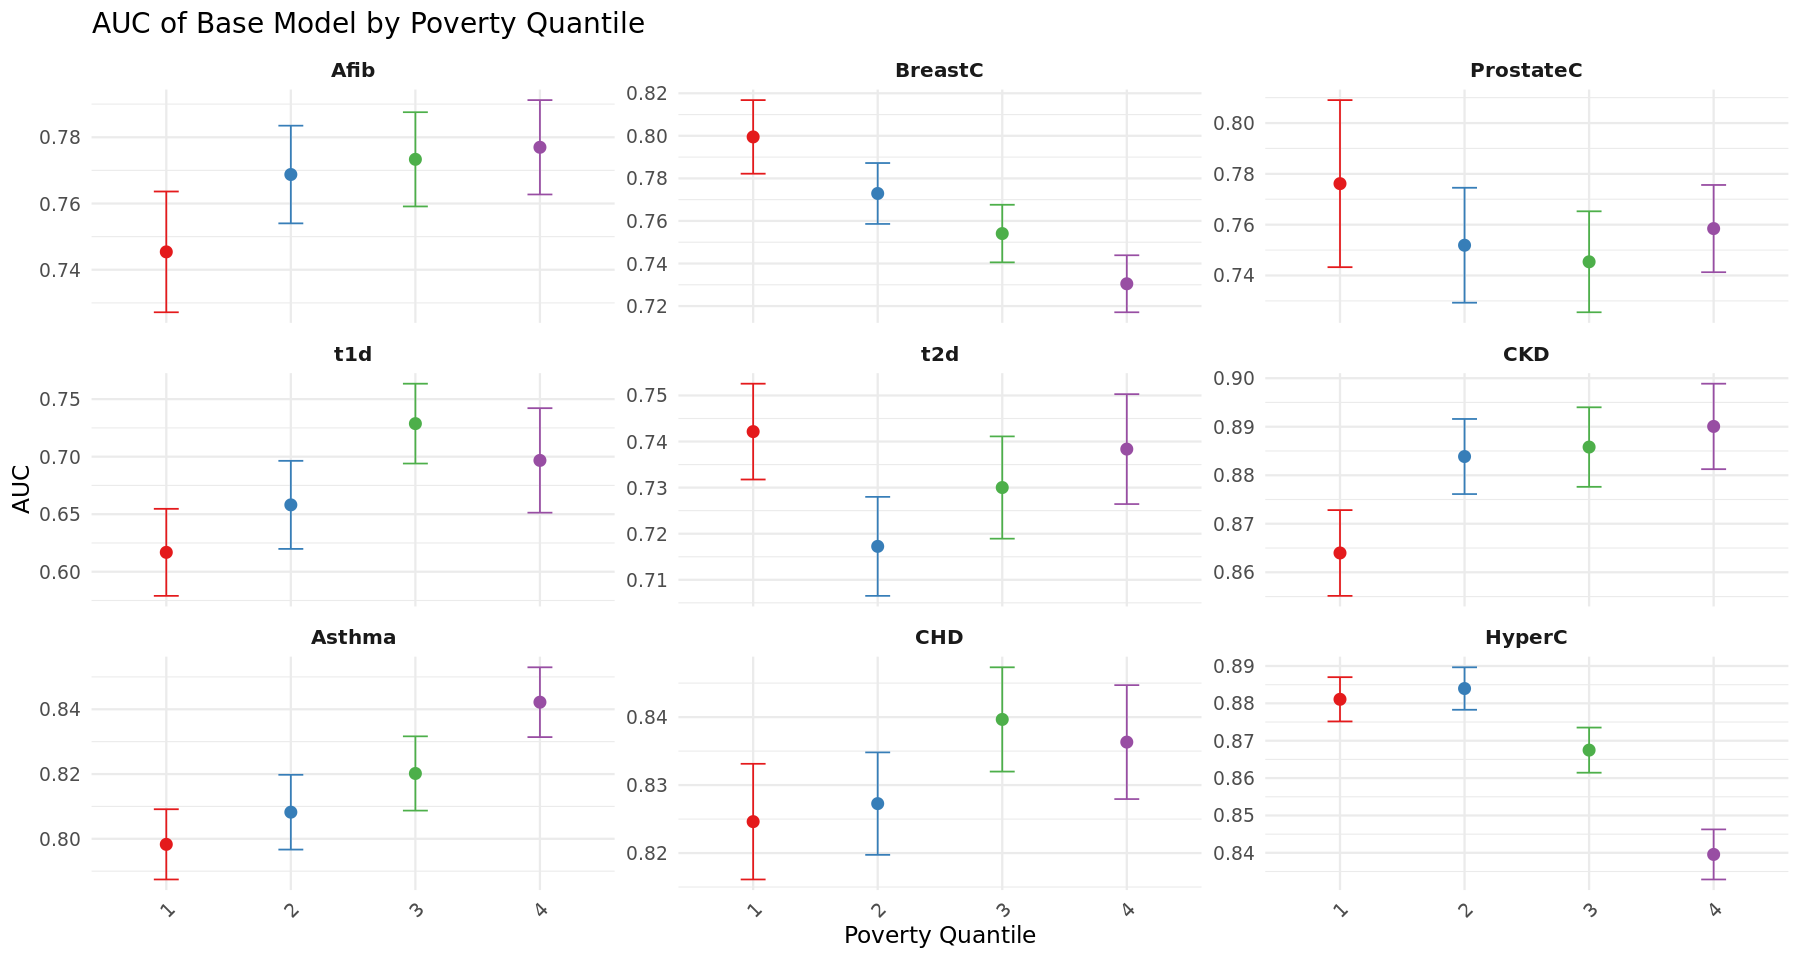

In [42]:

# Filter and prepare data for plotting
auc_plot_data <- results %>%
  select(Disease, Domain, Model, AUC, AUC_CI_Lower, AUC_CI_Upper, Poverty_Quantile) %>%
  filter(!is.na(AUC))  # Exclude rows with NA AUC values

 auc_plot_data$Poverty_Quantile <- factor(auc_plot_data$Poverty_Quantile)

auc_plot_data$Disease <- factor(auc_plot_data$Disease, levels = 
                                c("Afib", "BreastC", "ProstateC",
                                    "t1d", "t2d", "CKD",
                                 "Asthma", "CHD", "HyperC")) 

# Convert Poverty_Quantile to a factor
auc_plot_data$Poverty_Quantile <- factor(auc_plot_data$Poverty_Quantile)

# Create the plot
auc_plot <- ggplot(auc_plot_data, aes(x = Poverty_Quantile, y = AUC, color = Poverty_Quantile)) +
  geom_point(position = position_dodge(width = 0.5), size = 3) +  # Points for AUC
  geom_errorbar(aes(ymin = AUC_CI_Lower, ymax = AUC_CI_Upper), 
                position = position_dodge(width = 0.5), width = 0.2) +  # Error bars for 95% CI
  facet_wrap(~ Disease, scales = "free_y", ncol = 3) +  # Adjust the number of columns to make the figure wider
  scale_color_brewer(palette = "Set1", name = "Poverty Quantile") +  # Color by Poverty Quantile
  labs(
    title = "AUC of Base Model by Poverty Quantile",
    x = "Poverty Quantile",
    y = "AUC"
  ) +
  theme_minimal(base_size = 14) +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    strip.text = element_text(size = 12, face = "bold"),
    legend.title = element_text(face = "bold", hjust = .5)
  ) +
  theme(legend.position = "none")  # Remove the legend (optional)

# Set plot size for Jupyter Notebook
options(repr.plot.width = 15, repr.plot.height = 8)  # Set width and height
print(auc_plot)

# Save the plot (optional)
ggsave("auc_plot_with_ci.png", plot = auc_plot, width = 15, height = 8, dpi = 300)
